---
---

<h1><center><ins>Exercise Sheet 5</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp, cos

## Exercise 1 - Numerical derivative

**(A)** Compute the derivative of the following two functions:

$$ f_1(x) = x^2 + \cos(x) $$

$$ f_2(x) = \exp(x) - x^3 $$

in correspondence of at least $N = 50$ values $x_i$ ($i = 1, ..., N$) of the variable $x$ in the interval $[1,5]$. To do this, *write your own code to compute the derivatives numerically*.

**(B)** Compare the resulting values you get for the numerical derivatives with the corresponding analytic solutions. Calculate the value of the quantity $q$ for each function:

$$ q = \sum_{i=1}^N \frac{\left[d_i - f'(x_i) \right]}{f'(x_i)} $$

where $d_i$ are the values you obtained for the numerical derivatives for each of the $N$ abscissas, and $f'(x_i)$ are the analytical derivatives evaluated in points $x_i$. How does the value of $q$ change when changing the value of $h$ to compute the derivatives numerically? How do the values of $q$ compare for the two functions? Discuss your findings.

In [4]:
# Exercise 1.(A)

# The two functions from the task

f1 = lambda x: x**2 + np.cos(x)
f2 = lambda x: np.exp(x) - x**3

# 50 evenly spaced points between 1 and 5
x = np.linspace(1, 5, 50)

# Step size for the derivative
h = 1e-3

# Own numerical derivative: forward difference
d1 = (f1(x + h) - f1(x)) / h
d2 = (f2(x + h) - f2(x)) / h

# Show the first 5 values to check it works
print(d1[:5])
print(d2[:5])

[1.159259   1.28130436 1.40923041 1.54327251 1.6836253 ]
[-0.28335958 -0.56206713 -0.86108219 -1.17873117 -1.51319817]


In [5]:
# Exercise 1.(B)

# Exact derivatives, worked out by hand
df1 = lambda x: 2*x - np.sin(x)
df2 = lambda x: np.exp(x) - 3*x**2

# q: summed relative error between numerical and exact derivative
q1 = np.sum((d1 - df1(x)) / df1(x))
q2 = np.sum((d2 - df2(x)) / df2(x))

print(q1, q2)

0.01412067677660895 0.03659007434024807


In [6]:
# Try several step sizes and compare q
for h in [1e-1, 1e-2, 1e-3, 1e-5, 1e-8, 1e-12]:
    d1 = (f1(x + h) - f1(x)) / h
    d2 = (f2(x + h) - f2(x)) / h
    q1 = np.sum((d1 - df1(x)) / df1(x))
    q2 = np.sum((d2 - df2(x)) / df2(x))
    print(h, q1, q2)

0.1 1.4227821320074663 3.7130558270273295
0.01 0.14130513623067195 0.3664083773610801
0.001 0.01412067677660895 0.03659007434024807
1e-05 0.0001411959312942848 0.0003658436771951408
1e-08 1.4657696107178919e-07 7.801344193391512e-07
1e-12 0.006526763814437471 0.001905724598183204


Smaller h lowers q because the truncation error is proportional to h. Below about h = 10⁻⁸, q grows again because rounding errors dominate. q is larger for f2 because it has stronger curvature.

## Exercise 2 - Newton-Cotes formulas

In the file ```surface_luminosity.txt``` you will find the numerical function describing the surface luminosity $\Sigma$ of a globular star cluster as a function of the distance $R$ from its centre (projected on the plane of the sky). Compute the total luminosity $L$ of the system by performing the integral

$$ L = \int_0^{R_{\text{max}}} \Sigma(R) \, 2 \pi R \, dR $$

using the trapezoid rule and Simpson's rule, and compare the results you obtain. To do this, first choose one of these methods and implement **your own algorithm to compute the integral with it**; for the other method, use the corresponding built-in python function ```scipy.integrate.trapz``` or ```scipy.integrate.simps``` and familiarize on its usage.

In [7]:
# EXERCISE 2

# Load data: column 1 = radius R, column 2 = surface luminosity Sigma
R, Sigma = np.loadtxt("surface_luminosity.txt", unpack=True)

# Integrand: Sigma(R) * 2*pi*R (luminosity of a thin ring at radius R)
y = Sigma * 2 * np.pi * R

# Own trapezoid rule: works for unevenly spaced points
# Area of each strip = width * average height
def trapez(x, y):
    total = 0
    for i in range(len(x) - 1):
        width = x[i+1] - x[i]
        height = (y[i] + y[i+1]) / 2
        total = total + width * height
    return total

L_trapez = trapez(R, y)
print(L_trapez)

1285408.7095045173


In [8]:
from scipy.integrate import simpson

L_simpson = simpson(y, x=R)
print(L_trapez, L_simpson)
print("Unterschied in %:", abs(L_trapez - L_simpson) / L_simpson * 100)

1285408.7095045173 1282549.6319938095
Unterschied in %: 0.22292139340160672


Both methods give L ≈ 1.28 · 10⁶ and differ by only about 0.2 %. Simpson’s rule is more accurate because it fits parabolas instead of straight lines and follows the curvature of the function. The trapezoid rule is easy to implement for unevenly spaced data points like these.

## Exercise 3 - Gaussian Quadrature

**(A)** Compute the following integral by using a 4-point Gaussian quadrature. 

$$ I = \int_{-1}^{1} \cos(x) dx $$

To do this, use the Legendre polynomial of degree 4:

$$ P_4(x) = \frac{1}{8}(35 x^4 - 30 x^2 +3) $$

At this link: https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature you can find the roots of Legendre polynomials and the necessary weights to solve the integral (i.e., you do not have to calculate them all from scratch!).

**(B)** Compare the result with the ones you obtain when using a Legendre polynomial of degree 3, 2, and 1, and comment your findings.

In [9]:
# EXERCISE 3.(A)

# Exact value for comparison: integral of cos(x) from -1 to 1 = 2*sin(1)
I_exact = 2 * np.sin(1)

# 4-point Gauss-Legendre: nodes = roots of P4(x), weights from Wikipedia
a = np.sqrt(3/7 - 2/7 * np.sqrt(6/5))
b = np.sqrt(3/7 + 2/7 * np.sqrt(6/5))
nodes4 = np.array([-b, -a, a, b])
weights4 = np.array([(18 - np.sqrt(30))/36, (18 + np.sqrt(30))/36,
                     (18 + np.sqrt(30))/36, (18 - np.sqrt(30))/36])

# Check: the nodes really are roots of P4 (should print values close to 0)
P4 = lambda x: (35*x**4 - 30*x**2 + 3) / 8
print("P4 at the nodes:", P4(nodes4))

# Gaussian quadrature: integral = sum of weight * f(node)
I4 = np.sum(weights4 * np.cos(nodes4))
print("4-point Gauss:", I4)
print("Exact value:  ", I_exact)
print("Error:        ", abs(I4 - I_exact))

P4 at the nodes: [ 4.44089210e-16 -5.55111512e-17 -5.55111512e-17  4.44089210e-16]
4-point Gauss: 1.6829416886959736
Exact value:   1.682941969615793
Error:         2.809198194064777e-07


In [10]:
# EXERCISE 3.(B)

# Nodes and weights for degree 3, 2, 1 (from Wikipedia)
gauss = {
    4: (nodes4, weights4),
    3: (np.array([-np.sqrt(3/5), 0, np.sqrt(3/5)]), np.array([5/9, 8/9, 5/9])),
    2: (np.array([-1/np.sqrt(3), 1/np.sqrt(3)]), np.array([1, 1])),
    1: (np.array([0.0]), np.array([2.0])),
}

# Compute the integral for each degree and compare with the exact value
for n in [4, 3, 2, 1]:
    nodes, weights = gauss[n]
    I_n = np.sum(weights * np.cos(nodes))
    print(n, "points:", I_n, " error:", abs(I_n - I_exact))

4 points: 1.6829416886959736  error: 2.809198194064777e-07
3 points: 1.683003547726917  error: 6.157811112394995e-05
2 points: 1.6758236553899861  error: 0.007118314225806888
1 points: 2.0  error: 0.317058030384207


With only 4 function evaluations, Gaussian quadrature reaches an error of about 10⁻⁷. Each additional point reduces the error by roughly two orders of magnitude, because an n-point Gauss rule integrates polynomials up to degree 2n−1 exactly. With 1 point (the midpoint rule) the result is very poor. Gaussian quadrature is therefore extremely accurate with very few points, but it does not provide an error estimate by itself.

## Exercise 4 - Monte Carlo integration 

Consider the following integral:
$$ I = \int_0^1 \cos \left(\frac{\pi x}{2} \right) dx = \frac{2}{\pi} $$

**(A)** Compute the above integral and its variance by using the following Monte Carlo methods:

1. mean value

How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.



In [11]:
# EXERCISE 4.(A)

# Function to integrate and its exact integral
f = lambda x: np.cos(np.pi * x / 2)
I_exact = 2 / np.pi

# Monte Carlo mean value method on [0, 1]
def mc_mean(f, N):
    x = np.random.uniform(0, 1, N)          # N random points between 0 and 1
    fx = f(x)
    I = np.mean(fx)                         # integral = (b - a) * mean of f, here b - a = 1
    var = (np.mean(fx**2) - I**2) / N       # variance of the estimate
    return I, var

I, var = mc_mean(f, 1000)
print("MC integral:", I)
print("Exact value:", I_exact)
print("Variance:   ", var, " sigma:", np.sqrt(var))

MC integral: 0.6417411044989423
Exact value: 0.6366197723675814
Variance:    9.833529010147014e-05  sigma: 0.009916415184000221


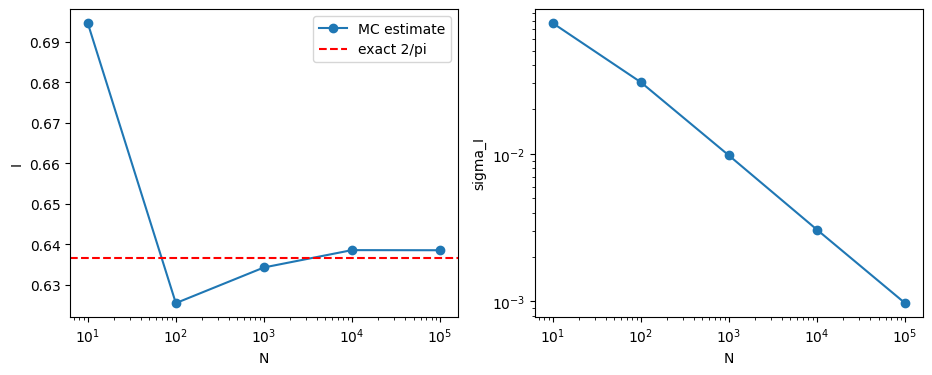

In [12]:
# EXERCISE 4.(B)

# Run the Monte Carlo integration for different numbers of points
Ns = [10, 100, 1000, 10000, 100000]
Is = []
sigmas = []
for N in Ns:
    I, var = mc_mean(f, N)
    Is.append(I)
    sigmas.append(np.sqrt(var))

# Plot I and sigma as a function of N (log scale on x)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(Ns, Is, "o-", label="MC estimate")
ax1.axhline(I_exact, color="red", linestyle="--", label="exact 2/pi")
ax1.set_xscale("log")
ax1.set_xlabel("N"); ax1.set_ylabel("I")
ax1.legend()

ax2.plot(Ns, sigmas, "o-")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("N"); ax2.set_ylabel("sigma_I")
plt.show()

The Monte Carlo estimate converges to the exact value 2/π ≈ 0.6366 as N increases. The standard deviation σ_I decreases proportionally to 1/√N: 100 times more points reduce the error only by a factor of 10. Monte Carlo integration is therefore slow compared to Simpson or Gaussian quadrature in one dimension, but it provides an error estimate directly.

## Exercise 5 - Monte Carlo integration continued (optional)

**(A)** Compute the above integral from Exercise 4 and its variance by using the other Monte Carlo methods covered in the lecture:

2. Importance sampling

Hint: for importance sampling, you can use the following weight function: 
$$w(x) = A \frac{1}{1+\left( \pi x/2 \right)^2}$$
where you can determine the normalization constant by imposing:
$$\int_0^1 w(x) dx = 1 = A \frac{2}{\pi} \arctan(\pi/2) \rightarrow A = \frac{\pi}{2 \arctan(\pi/2)}$$


How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.